# Jour 1 : entraîner un premier YOLO, tracé dans MLflow

**Version complétée** (squad `team-rocket`, membre `malgorzata`) : tous les TODO sont remplis.
Ce notebook entraîne et enregistre **ton run** dans MLflow. L'enregistrement du champion est fait par le chef de squad.

**Quand ?** Jour 1, une fois les images annotées dans CVAT et la tâche exportée par le chef d'équipe.

**Quoi ?** Ce notebook vous guide, étape par étape :

0. vérifier le GPU et installer les bibliothèques ;
1. renseigner vos paramètres (login, squad, membre, version, export CVAT) ;
2. vous connecter à MLflow (via le portail) et vérifier la connexion ;
3. décompresser l'export CVAT et le découper en `train` / `val` (≈ 80 / 20) ;
4. entraîner YOLO **dans un run MLflow** (paramètres, métriques, `best.pt`) ;
5. exporter le modèle en **ONNX** et le ranger dans le même run ;
6. regarder les résultats et quelques prédictions.

**Pourquoi ?** Tous vos entraînements sont tracés dans MLflow *dès le premier* : sans suivi, personne ne sait plus quel modèle est en production, avec quelles données ni quels paramètres.

**Prérequis**

- l'archive `.zip` exportée de CVAT (format *Ultralytics YOLO Detection 1.0*), déposée dans Colab (panneau *Fichiers*) ;
- le fichier `identifiants-<login>.json` téléchargé depuis votre profil du portail, déposé au même endroit ;
- un GPU : *Exécution > Modifier le type d'exécution > GPU (T4)*.

> **La métrique qui compte le plus est le rappel** (*recall*) : une case oubliée, c'est un créneau perdu.

## 0. GPU et installation

Activez le GPU **avant** d'installer quoi que ce soit : changer de type d'exécution réinitialise la session.

In [ ]:
# Vérification du GPU (doit afficher « Tesla T4 » ou similaire)
!nvidia-smi -L
%pip install -q ultralytics mlflow onnx onnxruntime onnxslim "albumentations>=2.0.0"

GPU 0: Tesla T4 (UUID: GPU-d71109bd-5ec3-bc7a-d5fe-b9d6e5c51fef)


## 1. Paramètres

| Élément | Convention | Exemple |
|---|---|---|
| `SQUAD` | nom d'équipe en minuscules, avec des tirets | `team-rocket`, `team-magma`, `team-aqua` |
| expérience MLflow | `flexistaff_<squad>` (commune à toute la squad) | `flexistaff_team-rocket` |
| nom du run | `<membre>_<version>` | `toto_v1` |
| modèle enregistré | `flexistaff_<squad>` | `flexistaff_team-rocket` |

`LOGIN` et `CVAT_ZIP` sont retrouvés automatiquement à partir des fichiers déposés dans le panneau *Fichiers*
(un seul `identifiants-*.json` et un seul `.zip`). Vous pouvez aussi les écrire en dur.

In [ ]:
import glob

SQUAD = "team-rocket"
MEMBRE = "malgorzata"
VERSION = "v1"                # version de votre entraînement : v1, puis v2, v3...
DATASET_VERSION = "v1"        # version du jeu de données (à changer si vous réexportez CVAT)

# Fichiers déposés dans le panneau Fichiers (détection automatique)
_creds = glob.glob("identifiants-*.json")
_zips = glob.glob("*.zip")
assert len(_creds) == 1, f"Déposez UN fichier identifiants-<login>.json (trouvé : {_creds})"
assert len(_zips) == 1, f"Déposez UNE archive .zip exportée de CVAT (trouvé : {_zips})"
CREDENTIALS = _creds[0]
LOGIN = CREDENTIALS[len("identifiants-"):-len(".json")]
CVAT_ZIP = _zips[0]

DATASET_DIR = "dataset"       # dossier de travail du jeu de données
RATIO_TRAIN = 0.8             # ≈ 80 % des images en train, 20 % en val
SEED = 42                     # graine du tirage : même découpage à chaque exécution

# Déduits des paramètres ci-dessus (ne pas modifier)
EXPERIMENT = f"flexistaff_{SQUAD}"
MODEL_NAME = f"flexistaff_{SQUAD}"
RUN_NAME = f"{MEMBRE}_{VERSION}"
print("Login :", LOGIN, "| export :", CVAT_ZIP)
print("Expérience :", EXPERIMENT, "| run :", RUN_NAME)

Login : malgorzata.r | export : FlexiStaff_annotations (1).zip
Expérience : flexistaff_team-rocket | run : malgorzata_v1


## 2. Connexion à MLflow

MLflow est protégé par le portail : le client doit présenter vos identifiants (les mêmes que pour CVAT).
Ils sont lus dans le fichier JSON et passés par variables d'environnement : ils ne sont **jamais** affichés ni écrits dans le notebook.
Vous n'avez *pas* besoin des identifiants S3 : les artefacts transitent par le serveur MLflow.

> Le fichier d'identifiants contient vos mots de passe : ne le committez jamais et ne le laissez pas dans un notebook partagé.

In [ ]:
import json
import os

import mlflow
import onnx
from mlflow import MlflowClient

with open(CREDENTIALS, encoding="utf-8") as f:
    creds = json.load(f)["mlflow"]
os.environ["MLFLOW_TRACKING_USERNAME"] = creds["username"]
os.environ["MLFLOW_TRACKING_PASSWORD"] = creds["password"]

mlflow.set_tracking_uri(creds["tracking_uri"])

# Test de connexion : on liste les expériences visibles
try:
    experiences = MlflowClient().search_experiments(max_results=5)
    print("Connexion MLflow OK :", [e.name for e in experiences])
except Exception as e:
    raise RuntimeError(f"Connexion à MLflow impossible : {e}\n"
                       "Vérifiez le fichier d'identifiants (dépôt dans le panneau Fichiers, bon login).") from e

mlflow.set_experiment(EXPERIMENT)   # créée si elle n'existe pas encore
print("Expérience :", EXPERIMENT)

# Garde-fou : un nom de run ne doit servir qu'une fois
deja = mlflow.search_runs(experiment_names=[EXPERIMENT],
                          filter_string=f"tags.mlflow.runName = '{RUN_NAME}'")
assert deja.empty, f"Le run {RUN_NAME} existe déjà : passez VERSION à la suivante (v2, v3...)."

Connexion MLflow OK : ['flexistaff_team-rocket', 'flexistaff_None', 'flexistaff_team-aqua', 'flexistaff_team-magma', 'rocket-team']
Expérience : flexistaff_team-rocket


## 3. Jeu de données : décompresser l'export CVAT et découper train / val

L'export CVAT (*Ultralytics YOLO Detection 1.0*) contient `data.yaml`, `images/` et `labels/`.
Ultralytics attend cette structure, avec **deux ensembles** : `train` (le modèle apprend) et `val` (on mesure sur des images qu'il n'a jamais vues) :

```
dataset/
├── data.yaml
├── images/{train,val}/   *.jpg
└── labels/{train,val}/   *.txt   (même nom que l'image)
```

Les **noms de classes sont lus dans le `data.yaml` de l'export** : ce sont les vôtres, ne les écrivez pas à la main.
On vérifie quand même que leur ordre est celui du guide de labellisation de la squad.

> Avec si peu d'images, les scores varieront beaucoup d'un tirage à l'autre : ne sur-interprétez pas un écart de quelques points.

In [ ]:
import random
import shutil
import zipfile
from pathlib import Path

import yaml

CLASSES_ATTENDUES = ["Titre_calendrier", "Date_case", "Ressource", "Evenement"]  # ordre CVAT de la squad

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
brut = Path("cvat_brut")
dataset = Path(DATASET_DIR)

# 1) Décompression de l'export CVAT (on repart d'un dossier propre)
for d in (brut, dataset):
    shutil.rmtree(d, ignore_errors=True)
with zipfile.ZipFile(CVAT_ZIP) as z:
    z.extractall(brut)

# 2) data.yaml de l'export : c'est lui qui donne les classes, dans l'ordre de CVAT
data_yamls = list(brut.rglob("data.yaml"))
assert data_yamls, "data.yaml introuvable : avez-vous exporté au format « Ultralytics YOLO Detection 1.0 » ?"
racine = data_yamls[0].parent
cfg = yaml.safe_load(data_yamls[0].read_text(encoding="utf-8"))
names = cfg["names"]
if isinstance(names, list):          # liste ou dictionnaire {0: nom, ...} : on normalise
    names = dict(enumerate(names))
names = {int(k): v for k, v in names.items()}
assert [names[i] for i in sorted(names)] == CLASSES_ATTENDUES, (
    f"Classes de l'export {names} différentes de {CLASSES_ATTENDUES} : vérifiez les labels CVAT.")

# 3) Images et annotations. CVAT reproduit l'arborescence du bucket :
#    images/train/<équipe>/<lot>/xxx.jpg  et  labels/train/<équipe>/<lot>/xxx.txt
images = sorted(p for p in (racine / "images").rglob("*") if p.suffix.lower() in IMG_EXT)
assert images, "Aucune image trouvée dans images/ de l'export."

def label_de(img):
    # le .txt a le même nom que l'image, dans labels/ (même sous-dossier)
    rel = img.relative_to(racine / "images").with_suffix(".txt")
    return racine / "labels" / rel

# 4) Découpage train / val (≈ 80 / 20), reproductible grâce à SEED
random.Random(SEED).shuffle(images)
n_train = min(max(1, round(len(images) * RATIO_TRAIN)), len(images) - 1)
parts = {"train": images[:n_train], "val": images[n_train:]}

def nom_unique(img):
    # « Team Galaxy/lot-1/img_001.jpg » -> « Team_Galaxy__lot-1__img_001.jpg » :
    # deux lots peuvent contenir des images de même nom, on garde le chemin pour ne rien écraser
    rel = img.relative_to(racine / "images")
    return "__".join(rel.parts).replace(" ", "_")

sans_label = 0
for nom_part, liste in parts.items():
    (dataset / "images" / nom_part).mkdir(parents=True, exist_ok=True)
    (dataset / "labels" / nom_part).mkdir(parents=True, exist_ok=True)
    for img in liste:
        nom = nom_unique(img)
        shutil.copy(img, dataset / "images" / nom_part / nom)
        lbl = label_de(img)
        dest = dataset / "labels" / nom_part / (Path(nom).stem + ".txt")
        if lbl.exists():
            shutil.copy(lbl, dest)
        else:
            dest.write_text("")      # image sans annotation : fichier vide
            sans_label += 1

# 5) Notre data.yaml (chemins absolus, mêmes classes que CVAT)
DATA_YAML = dataset / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(dataset.resolve()),
    "train": "images/train",
    "val": "images/val",
    "nc": len(names),
    "names": names,
}, allow_unicode=True, sort_keys=False), encoding="utf-8")

print(f"{len(images)} images : {len(parts['train'])} train / {len(parts['val'])} val")
print("Classes :", names)
if sans_label:
    print(f"⚠ {sans_label} image(s) sans annotation : normal pour quelques images vides, "
          "anormal si c'est la majorité (job pas terminé, mauvais export ?)")
assert sans_label < len(images), "Aucune annotation trouvée : vérifiez l'export CVAT."

# Contrôle : chaque classe doit apparaître en val, sinon son rappel n'est pas mesurable
from collections import Counter
def compte(part):
    c = Counter()
    for f in (dataset / "labels" / part).glob("*.txt"):
        c.update(names[int(l.split()[0])] for l in f.read_text().splitlines() if l.strip())
    return dict(c)
print("Boîtes train :", compte("train"))
print("Boîtes val   :", compte("val"))
absentes = set(names.values()) - set(compte("val"))
if absentes:
    print(f"⚠ Classes absentes de val : {absentes}. Changez SEED pour un autre tirage.")

40 images : 32 train / 8 val
Classes : {0: 'Titre_calendrier', 1: 'Date_case', 2: 'Ressource', 3: 'Evenement'}
Boîtes train : {'Date_case': 583, 'Evenement': 1384, 'Ressource': 120, 'Titre_calendrier': 28}
Boîtes val   : {'Evenement': 427, 'Titre_calendrier': 6, 'Ressource': 36, 'Date_case': 127}


## 3 bis. Augmentation des données : **après** le split, **sur train uniquement**

**Pourquoi après le split ?** Si on augmentait avant, une image de val et sa copie tournée de train seraient
presque identiques : le modèle « reconnaîtrait » la val et les scores seraient faussement bons.
**`val` reste intact** : on mesure sur des images non retouchées, comme en production.

**Pourquoi hors ligne ?** On fabrique des copies retouchées de chaque image de train (l'original est gardé),
avec uniquement des transformations **réalistes pour une photo de planning prise au téléphone** :

| Transformation | Réaliste ? | Choix |
|---|---|---|
| Miroir horizontal / vertical | ❌ un planning inversé n'existe pas (noms à droite, texte à l'envers) | **désactivé** |
| Mosaic (4 plannings collés) | ❌ casse la mise en page (titre en haut, noms à gauche) | **désactivé** |
| Rotation légère (± 5°) | ✅ photo prise un peu de travers | activée |
| Perspective | ✅ téléphone pas parfaitement à plat | activée |
| Luminosité / contraste, ombre | ✅ éclairage de bureau, ombre de la main | activée |
| Flou léger (mise au point, bougé) | ✅ mais **léger** : le guide n'annote que le texte lisible | activée |
| Bruit, compression JPEG, niveaux de gris | ✅ photo de téléphone, scan noir et blanc | activée |
| Changement de teinte | ❌ peut fausser un code couleur du planning | **désactivé** |

**Images synthétiques vs vraies photos.** Les images du générateur sont « trop propres » : elles reçoivent
des retouches **plus fortes et plus de copies**, pour ressembler à de vraies photos. Les vraies photos ont
déjà leurs défauts : retouches **légères**. Une image est considérée comme **vraie photo** si son chemin
contient un des mots de `REEL_MOTIFS` : **vérifiez le comptage affiché** et adaptez la liste à vos noms de fichiers.

train : {'synthetique': 32}
        ex. synthetique : ['train__team-rocket__lot-1__img001.jpg', 'train__team-rocket__lot-1__img003.jpg']
val   : {'synthetique': 8}
        ex. synthetique : ['train__team-rocket__lot-1__img002.jpg', 'train__team-rocket__lot-1__img006.jpg']
⚠ Aucune vraie photo en val : les scores risquent d'être optimistes par rapport à la production.

train : 32 originaux + 64 copies augmentées = 96 images | val : inchangé
Boîtes conservées dans les copies : 4223/4230 (les boîtes sorties de l'image à plus de 50 % sont retirées)


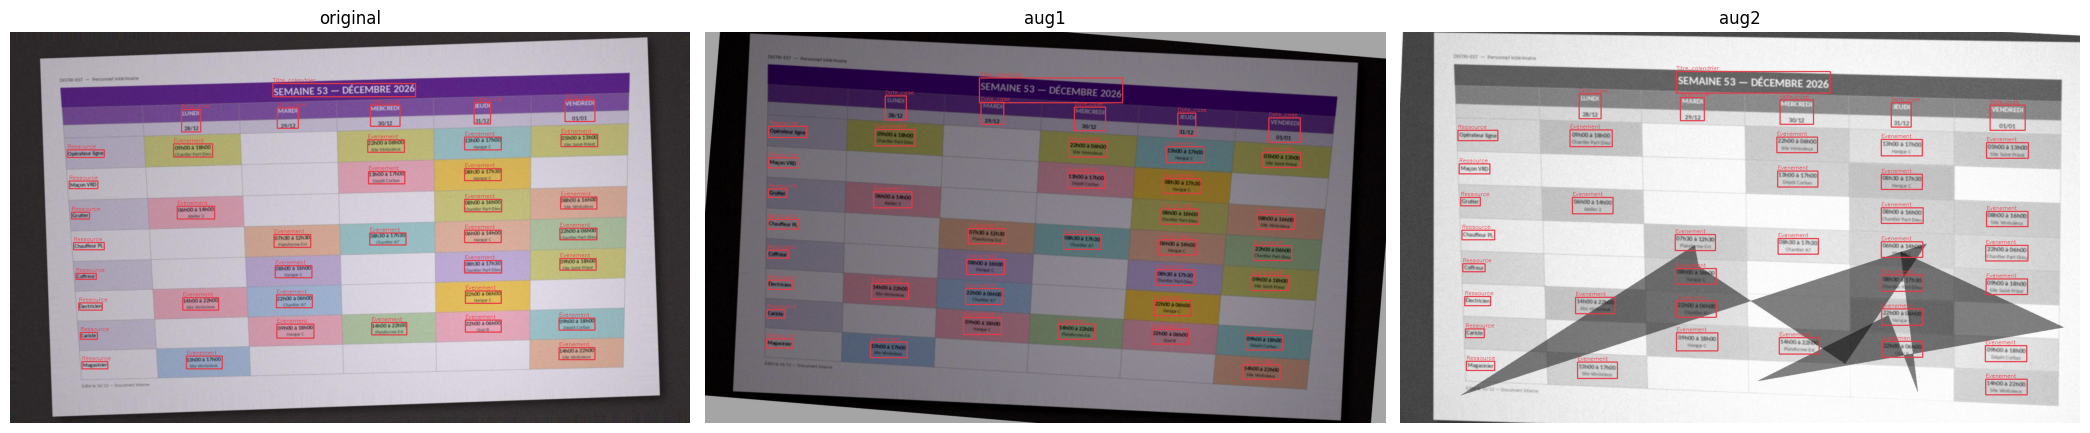

In [ ]:
import albumentations as A
import cv2
import matplotlib.pyplot as plt

AUGMENTATION_HORS_LIGNE = True                     # False = pas de copies (pour comparer deux runs)
COPIES = {"synthetique": 2, "reelle": 1}           # copies retouchées par image de train
REEL_MOTIFS = ["photo", "reel", "réel", "real", "scan"]   # mots présents dans le nom d'une VRAIE photo
ROTATION_MAX = 5                                   # degrés : au-delà, les boîtes gonflent trop

def source(nom):
    n = nom.lower()
    return "reelle" if any(m in n for m in REEL_MOTIFS) else "synthetique"

train_img = dataset / "images" / "train"
train_lbl = dataset / "labels" / "train"

# Composition des deux ensembles : la val devrait contenir de vraies photos (= la production)
for part in ("train", "val"):
    fichiers = sorted((dataset / "images" / part).iterdir())
    groupes = Counter(source(p.name) for p in fichiers)
    print(f"{part:5} : {dict(groupes)}")
    for g in groupes:
        print(f"        ex. {g} : {[p.name for p in fichiers if source(p.name) == g][:2]}")
if not any(source(p.name) == "reelle" for p in (dataset / "images" / "val").iterdir()):
    print("⚠ Aucune vraie photo en val : les scores risquent d'être optimistes par rapport à la production.")

def pipeline(fort):
    # fort = image synthétique (à « salir ») ; léger = vraie photo (déjà imparfaite)
    return A.Compose([
        A.Rotate(limit=ROTATION_MAX if fort else ROTATION_MAX / 2,
                 border_mode=cv2.BORDER_CONSTANT, fill=255, p=0.7),
        A.Perspective(scale=(0.02, 0.05), fill=255, p=0.4 if fort else 0.2),
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.8),
        A.RandomShadow(p=0.3 if fort else 0.1),
        A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=(3, 5))],
                p=0.5 if fort else 0.15),
        A.GaussNoise(std_range=(0.02, 0.06), p=0.3 if fort else 0.1),
        A.ImageCompression(quality_range=(50, 90), p=0.4 if fort else 0.2),
        A.ToGray(p=0.1),                               # scans noir et blanc
    ], bbox_params=A.BboxParams(format="yolo", label_fields=["classes"], min_visibility=0.5),
       seed=SEED)

PIPE = {"synthetique": pipeline(True), "reelle": pipeline(False)}

def lire_yolo(txt):
    # lit un .txt YOLO en recadrant les boîtes dans l'image (CVAT peut déborder de quelques pixels)
    boxes, cls = [], []
    if not txt.exists():
        return boxes, cls
    for l in txt.read_text().splitlines():
        if not l.strip():
            continue
        c, x, y, w, h = l.split()[:5]
        x, y, w, h = map(float, (x, y, w, h))
        x1, y1 = max(0.0, x - w / 2), max(0.0, y - h / 2)
        x2, y2 = min(1.0, x + w / 2), min(1.0, y + h / 2)
        if x2 - x1 > 1e-4 and y2 - y1 > 1e-4:
            boxes.append([round((x1 + x2) / 2, 6), round((y1 + y2) / 2, 6),
                          round(x2 - x1, 6) - 1e-6, round(y2 - y1, 6) - 1e-6])
            cls.append(int(float(c)))
    return boxes, cls

def ecrire_yolo(txt, boxes, cls):
    txt.write_text("".join(f"{int(c)} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n" for (x, y, w, h), c in zip(boxes, cls)))

# On repart propre si la cellule est relancée
for f in list(train_img.glob("*__aug*")) + list(train_lbl.glob("*__aug*")):
    f.unlink()

originaux = sorted(train_img.iterdir())
N_TRAIN_ORIGINAL = len(originaux)
N_AUG, boites_avant, boites_apres = 0, 0, 0
EXEMPLE = None
if AUGMENTATION_HORS_LIGNE:
    for img_path in originaux:
        src = source(img_path.name)
        image = cv2.imread(str(img_path))
        assert image is not None, f"Image illisible : {img_path}"
        boxes, cls = lire_yolo(train_lbl / f"{img_path.stem}.txt")
        for k in range(1, COPIES[src] + 1):
            out = PIPE[src](image=image, bboxes=boxes, classes=cls)
            nom = f"{img_path.stem}__aug{k}"
            cv2.imwrite(str(train_img / f"{nom}{img_path.suffix}"), out["image"])
            ecrire_yolo(train_lbl / f"{nom}.txt", out["bboxes"], out["classes"])
            boites_avant += len(boxes)
            boites_apres += len(out["bboxes"])
            N_AUG += 1
        if EXEMPLE is None and boxes:
            EXEMPLE = img_path

print(f"\ntrain : {N_TRAIN_ORIGINAL} originaux + {N_AUG} copies augmentées "
      f"= {N_TRAIN_ORIGINAL + N_AUG} images | val : inchangé")
if boites_avant:
    print(f"Boîtes conservées dans les copies : {boites_apres}/{boites_avant} "
          "(les boîtes sorties de l'image à plus de 50 % sont retirées)")

# Contrôle visuel : l'original et ses copies, avec leurs boîtes. Les boîtes doivent suivre le texte.
def dessiner(img_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    boxes, cls = lire_yolo(train_lbl / f"{img_path.stem}.txt")
    for (x, y, bw, bh), c in zip(boxes, cls):
        p1 = (int((x - bw / 2) * w), int((y - bh / 2) * h))
        p2 = (int((x + bw / 2) * w), int((y + bh / 2) * h))
        cv2.rectangle(img, p1, p2, (230, 57, 70), 2)
        cv2.putText(img, names[c], (p1[0], max(p1[1] - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (230, 57, 70), 1)
    return img

AUG_EXEMPLES = None
if EXEMPLE is not None:
    vues = [EXEMPLE] + sorted(train_img.glob(f"{EXEMPLE.stem}__aug*"))
    fig, axes = plt.subplots(1, len(vues), figsize=(7 * len(vues), 6), squeeze=False)
    for ax, p in zip(axes[0], vues):
        ax.imshow(dessiner(p)); ax.set_title("original" if p == EXEMPLE else p.stem.split("__")[-1]); ax.axis("off")
    plt.tight_layout()
    AUG_EXEMPLES = Path("aug_exemples.png")
    fig.savefig(AUG_EXEMPLES, dpi=80)
    plt.show()

## 4. Entraînement YOLO dans un run MLflow (et export ONNX, étape 5)

YOLO (*You Only Look Once*) détecte tous les objets en une seule passe : pour chaque zone, une **boîte**, une **classe** et une **confiance**.
On repart de poids pré-entraînés (`yolov8s.pt`) plutôt que de zéro.

| Élément d'un run | Ce qu'on y met |
|---|---|
| params | ce qu'on a *choisi* (modèle, epochs, taille d'image, version du dataset) |
| metrics | ce qu'on a *obtenu* (mAP50, précision, rappel) |
| artifacts | les fichiers *produits* (`best.pt`, courbes) : onglet *Artifacts* |
| logged models | le modèle *déployable* (ONNX), rattaché au run : onglet *Logged models* |
| tags | squad, version du dataset |

Hyperparamètres du `v1` : réglages de référence, identiques pour toute la squad, pour que les runs `*_v1` restent comparables.

In [ ]:
MODELE = "yolov8s.pt"   # small : bon compromis (n = plus rapide, m/l/x inutiles avec si peu de données)
EPOCHS = 50
IMGSZ = 640             # figée dans le fichier ONNX
BATCH = 16              # images par lot (réduisez à 8 en cas d'erreur de mémoire GPU)

# Augmentations faites PAR YOLO pendant l'entraînement : on coupe celles qui ne sont pas réalistes.
# (Les retouches photo sont déjà faites hors ligne en 3 bis : on ne les double pas.)
AUG_YOLO = {
    "fliplr": 0.0, "flipud": 0.0,                    # pas de miroir : un planning inversé n'existe pas
    "mosaic": 1.0, "mixup": 0.0, "copy_paste": 0.0,  # pas de plannings collés ensemble
    "degrees": 0.0, "shear": 0.0, "perspective": 0.0,  # rotation / perspective : faites en 3 bis
    "hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0,        # couleur / luminosité : faites en 3 bis
    "translate": 0.1, "scale": 0.3,                  # recadrage / zoom léger : réaliste, gardé
}

In [ ]:
from ultralytics import YOLO, settings

# Le suivi MLflow est fait à la main ci-dessous. On coupe celui intégré à Ultralytics, qui sinon
# relogue ses propres paramètres dans le même run (conflit) et change l'expérience courante.
settings.update({"mlflow": False})

model = YOLO(MODELE)   # poids pré-entraînés : on ne repart pas de zéro

with mlflow.start_run(run_name=RUN_NAME) as run:                       # <membre>_<version>
    RUN_ID = run.info.run_id
    mlflow.set_tags({"squad": SQUAD, "dataset": DATASET_VERSION, "membre": MEMBRE,
                     "augmentation": "hors_ligne" if AUGMENTATION_HORS_LIGNE else "aucune"})
    mlflow.log_params({"model": MODELE.replace(".pt", ""), "epochs": EPOCHS, "imgsz": IMGSZ,
                       "batch": BATCH, "dataset": DATASET_VERSION, "seed": SEED,
                       "n_train_original": N_TRAIN_ORIGINAL, "n_train_augmente": N_AUG,
                       "n_train": len(list(train_img.iterdir())), "n_val": len(parts["val"]),
                       "classes": ",".join(names.values()),
                       "aug_hors_ligne": AUGMENTATION_HORS_LIGNE,
                       "aug_copies_synthetique": COPIES["synthetique"], "aug_copies_reelle": COPIES["reelle"],
                       "aug_rotation_max": ROTATION_MAX,
                       **{f"yolo_{k}": v for k, v in AUG_YOLO.items()}})
    if AUG_EXEMPLES is not None:
        mlflow.log_artifact(str(AUG_EXEMPLES))

    res = model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                      **AUG_YOLO)

    # Métriques mesurées sur le jeu val
    mlflow.log_metrics({
        "mAP50": float(res.box.map50),
        "precision": float(res.box.mp),
        "recall": float(res.box.mr),          # celle qui compte le plus
    })
    # Rappel et mAP50 par classe : quelle classe le modèle oublie-t-il ?
    for i, c in enumerate(res.box.ap_class_index):
        p, r, ap50, _ = res.box.class_result(i)
        mlflow.log_metrics({f"recall_{names[int(c)]}": float(r),
                            f"mAP50_{names[int(c)]}": float(ap50)})

    best_pt = model.trainer.best    # runs/detect/train*/weights/best.pt
    mlflow.log_artifact(str(best_pt))
    save_dir = Path(model.trainer.save_dir)
    for f in ["results.png", "results.csv", "confusion_matrix.png", "confusion_matrix_normalized.png"]:
        if (save_dir / f).exists():
            mlflow.log_artifact(str(save_dir / f))   # courbes d'entraînement
    mlflow.log_artifact(str(DATA_YAML))

    # ---- Étape 5 : export ONNX, rangé dans le run ----
    onnx_path = YOLO(best_pt).export(format="onnx", imgsz=IMGSZ)
    modele_onnx = onnx.load(onnx_path)
    mlflow.onnx.log_model(modele_onnx, name="onnx", save_as_external_data=False)

print("Run :", RUN_NAME, "| run_id :", RUN_ID)
print(f"recall = {res.box.mr:.3f} | mAP50 = {res.box.map50:.3f} | precision = {res.box.mp:.3f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

## 5. Vérifier l'export ONNX dans le run

Cette cellule contrôle que le modèle ONNX est bien rangé dans le run : avec MLflow 3, il n'est pas dans l'onglet *Artifacts* mais dans *Logged models*.
Si elle échoue, corrigez puis relancez l'entraînement : un run terminé ne se complète pas proprement, ce sera un **nouveau run** (passez `VERSION` à `v2` plus haut).

Elle contrôle aussi le **format de sortie** du fichier ONNX : l'application et l'API attendent `[1, 4 + nb_classes, N]` (4 coordonnées de boîte, un score par classe, N candidats avant la suppression des doublons).

In [ ]:
# Vérification : le run contient-il bien best.pt (artefact) et le modèle ONNX (logged model) ?
client = MlflowClient()
fichiers = [a.path for a in client.list_artifacts(RUN_ID)]
print("Artefacts du run :", fichiers)

# MLflow 3 : le modèle ONNX n'est pas un artefact du run, c'est un « logged model » qui lui est rattaché
experience = client.get_run(RUN_ID).info.experiment_id
modeles = [m.name for m in mlflow.search_logged_models(experiment_ids=[experience], output_format="list")
           if m.source_run_id == RUN_ID]
print("Modèles du run :", modeles)

assert "onnx" in modeles, "Modèle ONNX absent du run : relancez l'entraînement avec VERSION suivante."
print("OK : ONNX présent dans le run.")

# Format de sortie attendu par l'application (CalEvent) et par l'API : [1, 4 + nb_classes, N]
onnx_local = Path(best_pt).with_suffix(".onnx")   # l'export écrit best.onnx à côté de best.pt
sortie = onnx.load(str(onnx_local)).graph.output[0]
forme = [d.dim_value or d.dim_param for d in sortie.type.tensor_type.shape.dim]
attendu = 4 + len(names)
print("Sortie ONNX :", forme)
assert len(forme) == 3 and forme[1] == attendu, (
    f"Sortie ONNX {forme} : l'application attend [1, {attendu}, N] (4 coordonnées + {len(names)} classes).\n"
    "Exportez sans option end2end ni nms (YOLOv8, YOLO11 ou YOLO26) ; "
    "une sortie [1, 300, 6] vient d'un export « sans NMS » (YOLOv10, ou YOLO26 avec end2end=True).")
print("OK : format de sortie compatible avec l'application.")

Artefacts du run : ['aug_exemples.png', 'best.pt', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'data.yaml', 'results.csv', 'results.png']
Modèles du run : ['onnx']
OK : ONNX présent dans le run.
Sortie ONNX : [1, 8, 8400]
OK : format de sortie compatible avec l'application.


## 6. Regarder les résultats

Retrouvez le run dans l'interface MLflow (lien du portail) : paramètres, métriques, `best.pt` (onglet *Artifacts*) et modèle ONNX (onglet *Logged models*).

In [ ]:
METRIQUE_CLE = "recall"   # une case oubliée = un créneau perdu

metriques = client.get_run(RUN_ID).data.metrics
print("Métriques sur val :")
for nom, val in sorted(metriques.items()):
    if nom in ("mAP50", "precision", "recall") or nom.startswith("recall_"):
        marque = "  <-- à regarder en premier" if nom == METRIQUE_CLE else ""
        print(f"  {nom:<26} {val:.3f}{marque}")

Métriques sur val :
  mAP50                      0.922
  precision                  0.864
  recall                     0.895  <-- à regarder en premier
  recall_Date_case           0.787
  recall_Evenement           0.957
  recall_Ressource           0.833
  recall_Titre_calendrier    1.000


Regarder des prédictions à l'œil reste le meilleur premier test. Ci-dessous : le modèle entraîné sur quelques images de `val` (jamais vues à l'entraînement).
Les boîtes manquantes sont des **oublis** (rappel trop bas) ; les boîtes en trop, des **fausses alarmes** (précision trop basse).

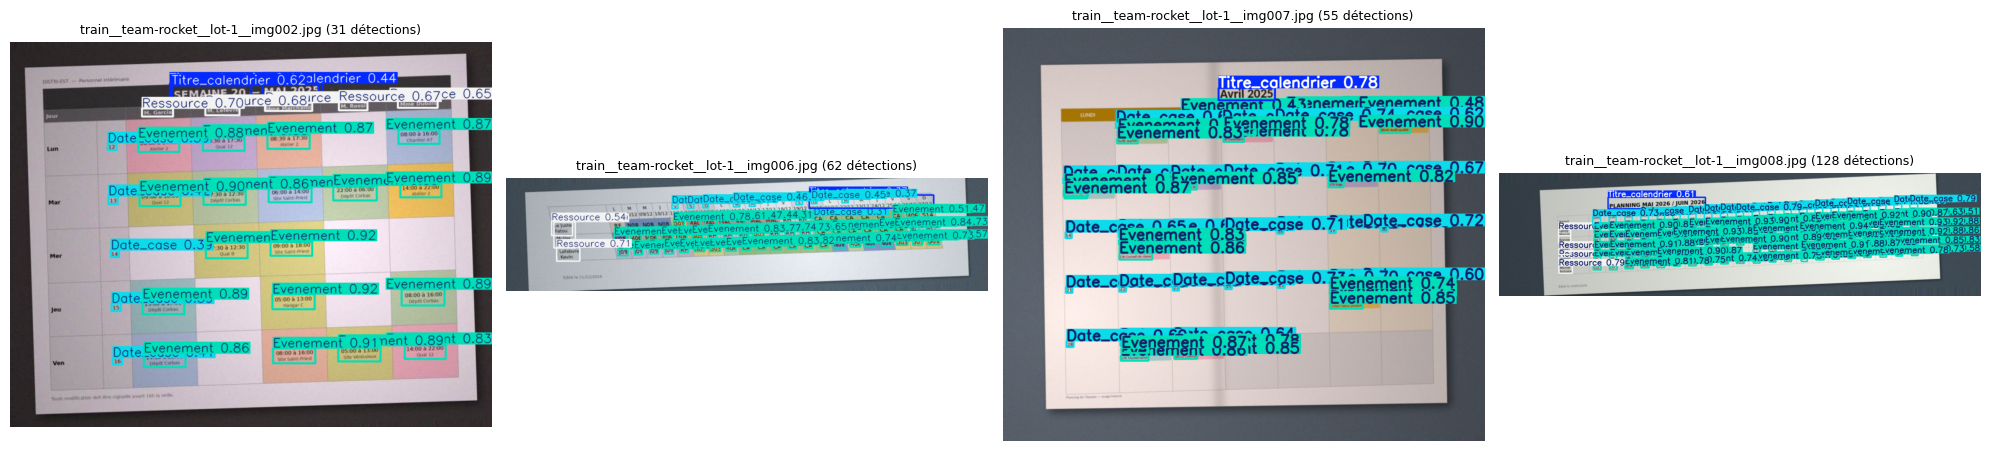

In [ ]:
import matplotlib.pyplot as plt

best = YOLO(str(best_pt))
echantillon = sorted((dataset / "images" / "val").glob("*"))[:4]

fig, axes = plt.subplots(1, len(echantillon), figsize=(5 * len(echantillon), 6), squeeze=False)
for ax, img in zip(axes[0], echantillon):
    r = best.predict(str(img), conf=0.25, imgsz=IMGSZ, verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1])          # BGR -> RGB
    ax.set_title(f"{img.name} ({len(r.boxes)} détections)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Enregistrer le champion (Registry)

Chaque membre a son run `<membre>_v1` avec son modèle ONNX. Comparez-les (tableau ci-dessous, ou *Compare* dans MLflow)
et choisissez le meilleur avec le critère de promotion de la formation :

1. le **rappel** d'abord : une case oubliée, c'est un créneau perdu ;
2. le **mAP50** pour départager deux modèles proches ;
3. c'est le **chef de squad** qui décide.

> **Jour 1 : le premier modèle devient `champion`.** Aucun champion n'existe encore, donc le meilleur `v1` de la squad prend cet alias.
> Dès le jour 2, **ne remplacez plus** le champion directement : les nouveaux modèles reçoivent l'alias `challenger`,
> on les compare au champion, et le chef décide de la promotion.
> **Seul le chef enregistre le modèle de la squad** : mettez-vous d'accord avant d'exécuter les cellules suivantes.

On utilise des **alias** (`champion`, `challenger`), pas les anciens « stages ». Le registre contient ensuite une version
du modèle `flexistaff_<squad>`, que chargent le notebook de test OCR (jour 2) et l'application (jour 3).

> N'utilisez **pas** `with mlflow.start_run(run_id=...)` pour compléter un run terminé : MLflow réécrit son heure de fin.
> L'enregistrement ci-dessous ne modifie pas le run.

### 7.1 Comparer les runs de la squad (lecture seule)

Le rappel est arrondi à 2 décimales pour le tri : avec quelques images en val, un point d'écart n'est pas significatif.

In [ ]:
import pandas as pd
from mlflow import MlflowClient
from mlflow.exceptions import MlflowException

client = MlflowClient()

runs = mlflow.search_runs(experiment_names=[EXPERIMENT]).dropna(subset=["metrics.recall"])
classement = (runs.assign(_r=runs["metrics.recall"].round(2))
                  .sort_values(["_r", "metrics.mAP50", "metrics.precision"], ascending=False)
                  [["tags.mlflow.runName", "metrics.recall", "metrics.mAP50", "metrics.precision", "run_id"]]
                  .rename(columns=lambda c: c.split(".")[-1])
                  .reset_index(drop=True))
classement.index += 1
display(classement.round(3))

# Un champion existe-t-il déjà ?
try:
    actuel = client.get_model_version_by_alias(MODEL_NAME, "champion")
    print(f"Champion actuel : {MODEL_NAME} version {actuel.version} (run {actuel.run_id})")
except MlflowException:
    actuel = None
    print(f"Aucun champion pour {MODEL_NAME} : le premier modèle enregistré deviendra champion.")

### 7.2 Enregistrer le modèle choisi et poser l'alias (chef de squad)

`RUN_ID_CHOISI` = identifiant du run retenu. Ici : ton run `malgorzata_v1`
(rappel 0,895, mAP50 0,922). Remplace-le par celui d'un coéquipier si le classement en désigne un meilleur.

Garde-fous de la cellule :
- elle vérifie que le run contient bien le modèle **ONNX** (sinon l'application n'aurait rien à charger) ;
- elle **refuse de remplacer un champion existant** : à partir du jour 2, utilisez `ALIAS = "challenger"`
  (ou `REMPLACER_CHAMPION = True` seulement sur décision du chef) ;
- elle note dans la version enregistrée **d'où vient le modèle** (run, rappel, mAP50) : traçabilité.

In [ ]:
RUN_ID_CHOISI = "4298fc34c04a406594d039a45cf36bae"   # malgorzata_v1 (ou le run_id d'un coéquipier)
ALIAS = "champion"             # "champion" aujourd'hui (jour 1) ; "challenger" à partir du jour 2
REMPLACER_CHAMPION = False     # True uniquement si le chef décide de promouvoir un nouveau champion

assert RUN_ID_CHOISI and ALIAS, "Complétez RUN_ID_CHOISI et ALIAS."

# 1) Le run existe-t-il, et contient-il le modèle ONNX ?
run_choisi = client.get_run(RUN_ID_CHOISI)
nom_run = run_choisi.data.tags.get("mlflow.runName", RUN_ID_CHOISI)
m = run_choisi.data.metrics
modeles_run = [lm.name for lm in mlflow.search_logged_models(
                   experiment_ids=[run_choisi.info.experiment_id], output_format="list")
               if lm.source_run_id == RUN_ID_CHOISI]
assert "onnx" in modeles_run, f"Le run {nom_run} ne contient pas de modèle ONNX : impossible de l'enregistrer."
print(f"Run choisi : {nom_run} | recall {m.get('recall', float('nan')):.3f} "
      f"| mAP50 {m.get('mAP50', float('nan')):.3f} | precision {m.get('precision', float('nan')):.3f}")

# 2) Ne pas écraser un champion existant par erreur
if ALIAS == "champion":
    try:
        actuel = client.get_model_version_by_alias(MODEL_NAME, "champion")
    except MlflowException:
        actuel = None
    if actuel is not None and actuel.run_id == RUN_ID_CHOISI:
        raise SystemExit(f"Ce run est déjà le champion (version {actuel.version}) : rien à faire.")
    assert actuel is None or REMPLACER_CHAMPION, (
        f"Un champion existe déjà (version {actuel.version}). À partir du jour 2, enregistrez avec "
        "ALIAS = 'challenger' ; ne passez REMPLACER_CHAMPION = True que sur décision du chef.")

# 3) Enregistrement dans le registre + alias
mv = mlflow.register_model(f"runs:/{RUN_ID_CHOISI}/onnx", MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, ALIAS, mv.version)

# 4) Traçabilité : d'où vient cette version ?
client.update_model_version(MODEL_NAME, mv.version,
    description=f"{nom_run} : recall {m.get('recall', 0):.3f}, mAP50 {m.get('mAP50', 0):.3f}, "
                f"precision {m.get('precision', 0):.3f} (dataset {run_choisi.data.tags.get('dataset', '?')})")
for cle in ("recall", "mAP50", "precision"):
    if cle in m:
        client.set_model_version_tag(MODEL_NAME, mv.version, cle, f"{m[cle]:.3f}")
client.set_model_version_tag(MODEL_NAME, mv.version, "run_name", nom_run)

print(f"✅ {MODEL_NAME} version {mv.version} -> alias « {ALIAS} »")

### 7.3 Vérifier : télécharger le modèle depuis le registre

On recharge le modèle **par son alias**, exactement comme le feront le notebook OCR (jour 2) et l'application (jour 3),
et on contrôle son format de sortie.

In [ ]:
import shutil
import onnx
from pathlib import Path

shutil.rmtree("champion", ignore_errors=True)
mlflow.artifacts.download_artifacts(f"models:/{MODEL_NAME}@{ALIAS}", dst_path="champion")
fichiers_onnx = sorted(Path("champion").rglob("*.onnx"))
print(fichiers_onnx)                      # -> champion/model.onnx
assert fichiers_onnx, "Aucun fichier ONNX téléchargé."

modele_reg = onnx.load(str(fichiers_onnx[0]))
forme = [d.dim_value or d.dim_param for d in modele_reg.graph.output[0].type.tensor_type.shape.dim]
meta = {p.key: p.value for p in modele_reg.metadata_props}
print("Sortie ONNX :", forme)             # attendu : [1, 8, 8400] pour 4 classes
print("Classes rangées dans le fichier :", meta.get("names"))

### 7.4 Fiche du modèle : vos classes → les rôles de CalEvent (chef de squad)

CalEvent ne connaît pas **vos** noms de classes : il lit des **rôles** (`calendar`, `month_header`, `day_header_row`,
`date_cell`, `event`, `resource_header`). Le tag `class_map` posé sur le modèle enregistré lui dit lequel est lequel ;
il le relit tout seul au rechargement (↻), pour le champion comme pour les futurs challengers.

| Classe Team Rocket | Rôle CalEvent |
|---|---|
| `Titre_calendrier` | `month_header` |
| `Date_case` | `date_cell` (à valider par le chef) |
| `Ressource` | `resource_header` |
| `Evenement` | `event` |

In [ ]:
CLASS_MAP = "Titre_calendrier=month_header,Date_case=date_cell,Ressource=resource_header,Evenement=event"

# Contrôle : chaque classe citée doit exister, et chaque rôle doit être connu de CalEvent
ROLES = {"calendar", "month_header", "day_header_row", "date_cell", "event", "resource_header"}
nos_classes = set(names.values())
for paire in CLASS_MAP.split(","):
    classe, role = paire.split("=")
    assert classe in nos_classes, f"Classe inconnue dans CLASS_MAP : {classe} (vos classes : {nos_classes})"
    assert role in ROLES, f"Rôle inconnu dans CLASS_MAP : {role} (rôles possibles : {ROLES})"

print("Vos classes :", list(names.values()))
client.set_registered_model_tag(MODEL_NAME, "class_map", CLASS_MAP)
print(f"Tag class_map posé sur {MODEL_NAME} : {CLASS_MAP}")

## Checklist de fin de journée

- [ ] Un entraînement s'est terminé sans erreur
- [ ] Ce run apparaît dans MLflow (paramètres, métriques, `best.pt`, modèle ONNX, tags squad et dataset)
- [ ] Vous avez regardé une prédiction (idéalement sur une vraie photo)
- [ ] Le meilleur `v1` de la squad est enregistré avec l'alias `champion` et son tag `class_map` (chef)
- [ ] Ce notebook (**sans le fichier d'identifiants**) est poussé dans `ai_training/` du fork de la squad

## Pour les versions suivantes (v2, v3...) : améliorer le rappel

Changez **un seul réglage à la fois** et passez `VERSION` à la suivante :
- `AUGMENTATION_HORS_LIGNE = False` : un run sans copies, pour mesurer ce que l'augmentation apporte ;
- `IMGSZ = 960` : les boîtes `Ressource` et `Evenement` sont petites, faciles à rater à 640 px ;
- `"mosaic": 1.0` dans `AUG_YOLO` : peu réaliste, mais souvent utile avec très peu d'images : à tester ;
- plus d'images annotées (lot 2), surtout de **vraies photos** : le levier le plus efficace.